In [6]:
import sys
# Temporarily mask torch to bypass the circular import bug in Python 3.13
sys.modules['torch'] = None

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

Iris Dataset Features and Sample Rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  


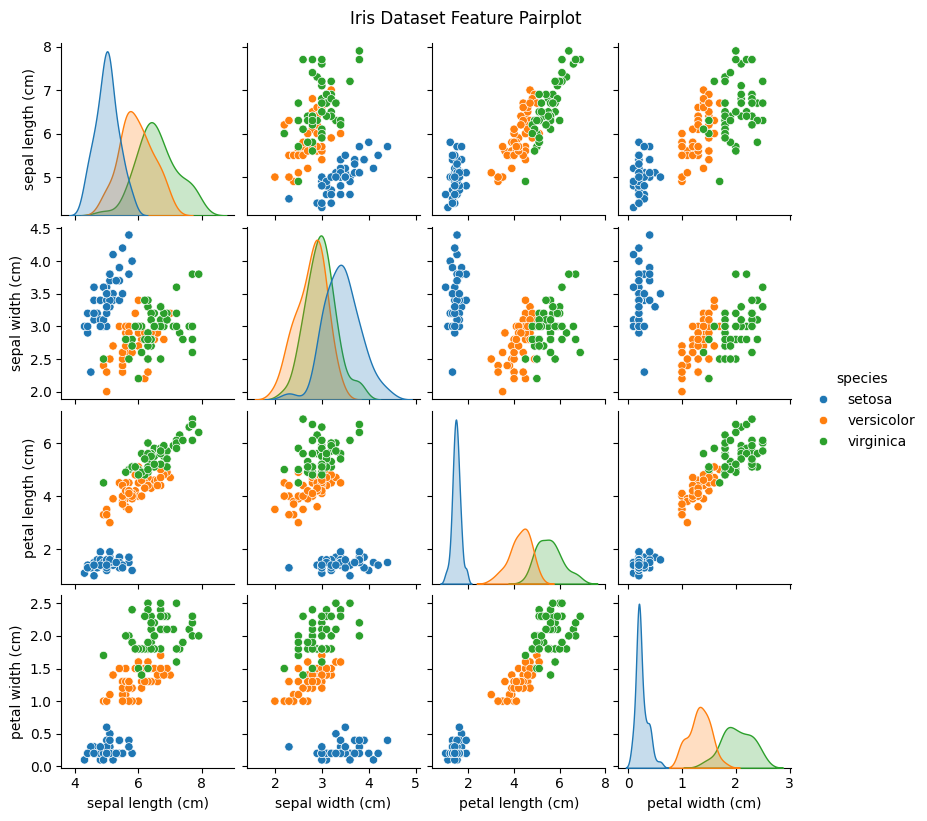

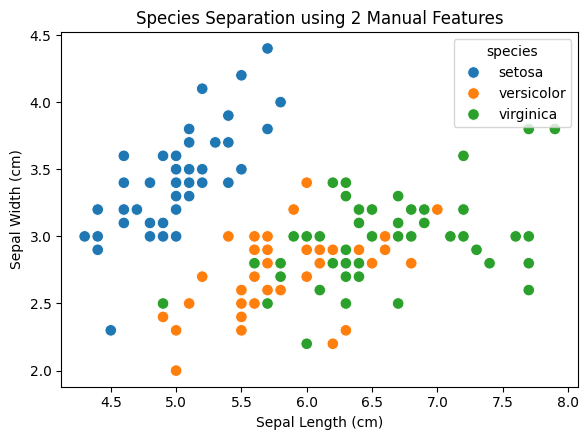

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


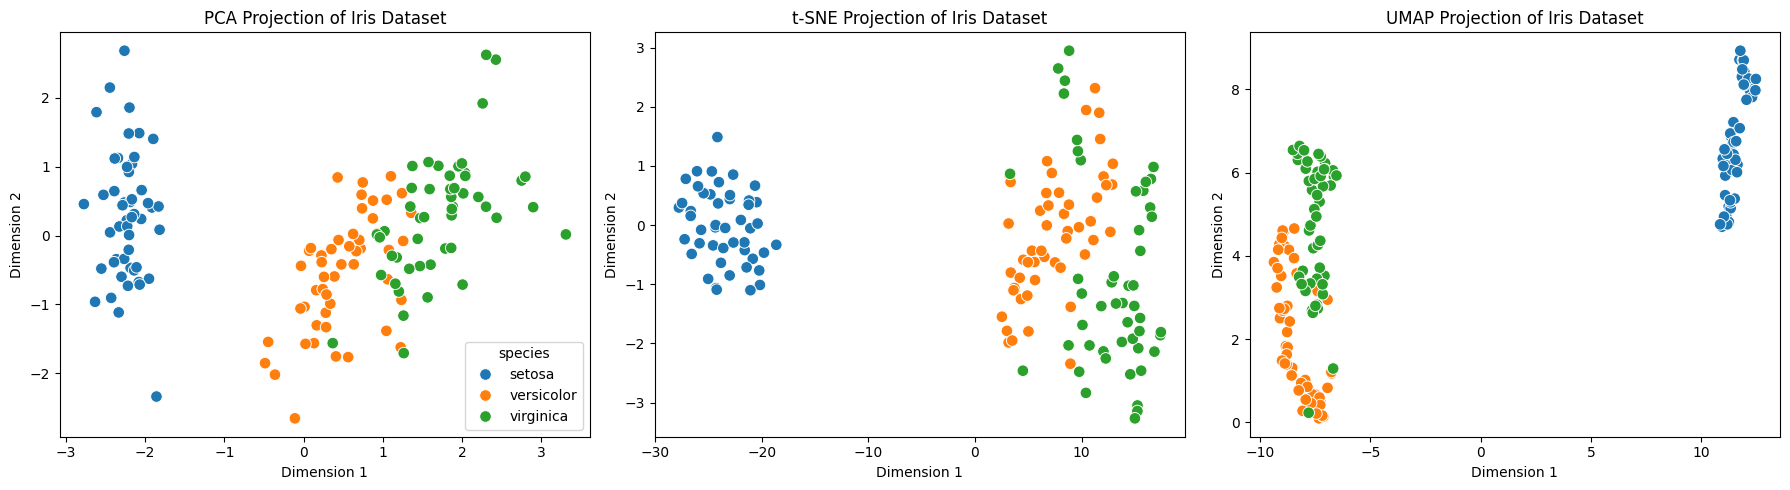

In [9]:
# 1. Load the Iris dataset, examine features, and plot a pairplot
iris = load_iris()
iris_df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
iris_df['species'] = [iris.target_names[i] for i in iris.target]

print("Iris Dataset Features and Sample Rows:")
print(iris_df.head())

# Visualizing initial features
sns.pairplot(iris_df, hue='species', height=2.0)
plt.suptitle("Iris Dataset Feature Pairplot", y=1.02)
plt.show()

# 2. Plot species using only 2 features (Sepal Length vs Sepal Width)
plt.figure(figsize=(6, 4.5))
sns.scatterplot(data=iris_df, x='sepal length (cm)', y='sepal width (cm)', hue='species', s=70)
plt.title("Species Separation using 2 Manual Features")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
plt.tight_layout()
plt.show()

# 3. Squeeze all 4 features into a 2D plot using PCA, t-SNE, and UMAP
X = iris.data
y = iris.target
species_labels = [iris.target_names[i] for i in y]

# Standardize features first (highly recommended for distance-based reduction methods)
X_scaled = StandardScaler().fit_transform(X)

# Apply PCA
pca_res = PCA(n_components=2).fit_transform(X_scaled)

# Apply t-SNE
tsne_res = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X_scaled)

# Apply UMAP
umap_res = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=42).fit_transform(X_scaled)

# 4. Plot outputs side-by-side to compare how well they group species
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
reductions = [('PCA', pca_res), ('t-SNE', tsne_res), ('UMAP', umap_res)]

for ax, (title, projection) in zip(axes, reductions):
    plot_data = pd.DataFrame(projection, columns=['Dimension 1', 'Dimension 2'])
    plot_data['species'] = species_labels
    sns.scatterplot(data=plot_data, x='Dimension 1', y='Dimension 2', hue='species', ax=ax, s=70, legend=(title == 'PCA'))
    ax.set_title(f"{title} Projection of Iris Dataset")

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


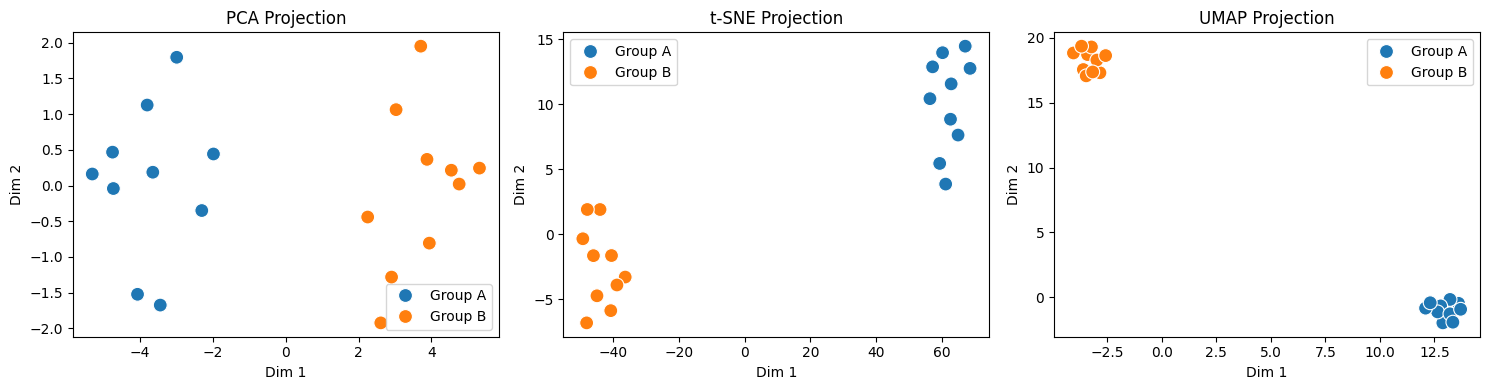

In [7]:
# --- DATASET GENERATION (Do not change) ---
np.random.seed(42)
data = np.random.randn(20, 4)
data[10:, :] += 3.5  # Create 2 groups
labels = ['Group A']*10 + ['Group B']*10
df = pd.DataFrame(data, columns=['F1', 'F2', 'F3', 'F4'])

X_scaled = df.values

# PCA
pca_res = PCA(n_components=2).fit_transform(X_scaled)

# t-SNE Preplexity Less than Number Of Samples
tsne_res = TSNE(n_components=2, perplexity=5, random_state=42).fit_transform(X_scaled)

# UMAP
umap_res = umap.UMAP(n_components=2, n_neighbors=5, random_state=42).fit_transform(X_scaled)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
results = [('PCA', pca_res), ('t-SNE', tsne_res), ('UMAP', umap_res)]

for ax, (title, res_data) in zip(axes, results):
    plot_df = pd.DataFrame(res_data, columns=['Dim 1', 'Dim 2'])
    # One Syntax Error : "LINE" , Added Hue For Two Disntict Groups
    sns.scatterplot(data=plot_df, x='Dim 1', y='Dim 2', hue=labels, ax=ax, s=100)
    ax.set_title(f"{title} Projection")

plt.tight_layout()
plt.show()